# 11 — Reverse Causation Check: Does Price Momentum Lead Future Rate-of-Change?

**Purpose.** Tests the *reverse* direction from `06_eda.ipynb`: does county price momentum
predict *future* mortgage rate-of-change, rather than the direction notebook 06 already tested
(does rate-of-change predict future decline risk)?

**Why this notebook exists.** Notebook 06's lag sweep found that `mortgage_rate_roc` is most
correlated with next-quarter decline risk at a 12-month lag, but with a **negative** sign
(r = -0.0521, 95% CI [-0.0568, -0.0474]) -- the opposite of the positive sign the stated
hypothesis expected (rising rates -> higher borrowing cost -> more decline risk). See
`outputs/eda_summary.json` (`sign_matches_hypothesis: false`). This was flagged at the time as
a face-validity surprise, not smoothed over.

A plausible explanation, written into `notebooks/10_final_evaluation.ipynb`'s Final write-up
as a stated limitation (the "Option A" paragraph): the Federal Reserve doesn't set mortgage
rate policy in a vacuum -- it responds to economic conditions, including a cooling housing
market. So part of the observed correlation plausibly runs in both directions at once, a
feedback loop rather than a one-way causal arrow.

**This notebook investigates that explanation directly**, rather than leaving it as an
untested story. It does not re-derive anything notebook 06 already settled, and it does not
modify or require re-running any of Phases 0-6 -- it's a supporting check, kept outside the
numbered phase sequence, the same way `00_zhvi_smoothing_check.ipynb` and
`04_teammate_pandas_comparison.ipynb` already are.

**Business question this answers.** If weakening national home-price momentum is followed by
future mortgage-rate cuts (and strengthening momentum by future rate increases), that's
evidence for the feedback-loop explanation behind notebook 10's Option A paragraph. If it
isn't, that paragraph should say so plainly rather than implying the explanation was
confirmed.

## 1. Setup

In [1]:
import os
import json

import numpy as np
import pandas as pd
from scipy import stats
from sqlalchemy import text

from housing_risk.config import get_engine, TRAIN_END
from housing_risk.features import shift_by_calendar_months

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 20)

Imports `shift_by_calendar_months` from `src/housing_risk/features.py` directly rather than
redefining it (unlike notebook 06, which had to duplicate this logic before `features.py`
existed) -- this is the project's real, tested implementation.

## 2. Connect to Postgres

Same convention used throughout the project: reads `PGUSER` / `PGPASSWORD` / `PGHOST` /
`PGPORT` / `PGDATABASE` via `src/housing_risk/config.py`.

In [2]:
engine = get_engine()

with engine.connect() as conn:
    print(conn.execute(text("SELECT version();")).scalar())

PostgreSQL 15.18 (Homebrew) on aarch64-apple-darwin25.4.0, compiled by Apple clang version 21.0.0 (clang-2100.0.123.102), 64-bit


## 3. Load training-only data

Both loads are filtered at the SQL level (`month <= TRAIN_END`) so no embargo- or test-period
row is ever loaded into this process, matching notebook 06 Section 3's discipline. The
boundary is asserted afterward rather than just trusted.

In [3]:
with engine.connect() as conn:
    has_county_month = conn.execute(
        text("SELECT to_regclass('county_month_check') IS NOT NULL")
    ).scalar()
    has_mortgage = conn.execute(
        text("SELECT to_regclass('mortgage_monthly') IS NOT NULL")
    ).scalar()
assert has_county_month, (
    "county_month_check doesn't exist yet -- run 03_join_sql_load.ipynb first."
)
assert has_mortgage, (
    "mortgage_monthly doesn't exist yet -- run 02_fred_ingest_clean.ipynb first."
)

zhvi_query = (
    "SELECT county_fips, month, zhvi FROM county_month_check "
    "WHERE month::date <= %(train_end)s"  # month is stored as TEXT; cast before comparing
)
county_month = pd.read_sql(zhvi_query, engine, params={"train_end": TRAIN_END})
county_month["month"] = pd.to_datetime(county_month["month"])

assert county_month["month"].max() <= TRAIN_END, (
    f"training-only filter failed: max month {county_month['month'].max()} > TRAIN_END {TRAIN_END}"
)
print(f"{len(county_month):,} training-only county-month rows, "
      f"{county_month['county_fips'].nunique():,} counties")
print(f"range: {county_month['month'].min().date()} to {county_month['month'].max().date()}")

# mortgage_monthly is a national series starting well before Zillow's coverage (1971) --
# loaded with no date filter so no rate-side warm-up months are lost. Any row not needed
# downstream is dropped naturally by later merges.
rate_query = "SELECT month, mortgage_rate FROM mortgage_monthly ORDER BY month"
mortgage_monthly = pd.read_sql(rate_query, engine)
mortgage_monthly["month"] = pd.to_datetime(mortgage_monthly["month"])
print(f"\n{len(mortgage_monthly):,} mortgage_monthly rows, "
      f"range {mortgage_monthly['month'].min().date()} to {mortgage_monthly['month'].max().date()}")

529,214 training-only county-month rows, 3,021 counties
range: 2000-01-31 to 2021-09-30

666 mortgage_monthly rows, range 1971-04-30 to 2026-09-30


## 4. Build a national momentum series

`mortgage_rate` has no county dimension -- it's a single national value shared by every county
each month (per `features.py`'s own docstring). So this comparison needs a single national
momentum series to correlate against it, not one series per county.

**Aggregation choice, stated explicitly:** county-level `zhvi` is aggregated to a national
series using the **median** across counties per month, not the mean, specifically to avoid a
handful of high-value coastal counties dominating a national figure.

In [4]:
national_zhvi = (
    county_month.groupby("month")["zhvi"]
    .median()
    .rename("national_zhvi")
    .reset_index()
    .sort_values("month")
    .reset_index(drop=True)
)
print(f"{len(national_zhvi):,} national monthly ZHVI rows")
national_zhvi.head()

261 national monthly ZHVI rows


,month,national_zhvi
0,2000-01-31,99177.614411
1,2000-02-29,99400.029773
2,2000-03-31,99650.828420
3,2000-04-30,99936.442060
4,2000-05-31,100392.659420


Momentum is computed on this single national series the same way `compute_momentum` does per
county in `features.py`, reusing `shift_by_calendar_months` rather than redefining the
date-shift logic.

**Window choice:** 3 months, matching `features.py`'s `INTERACTION_MOMENTUM_COL =
"momentum_3m"` -- the same momentum window already tied to the rate-of-change interaction term
this whole investigation traces back to.

In [5]:
NATIONAL_MOMENTUM_LAG_MONTHS = 3  # matches features.py's momentum_3m / INTERACTION_MOMENTUM_COL

past_national_zhvi = shift_by_calendar_months(
    national_zhvi, "national_zhvi", -NATIONAL_MOMENTUM_LAG_MONTHS
)
national_zhvi["national_momentum_3m"] = (
    national_zhvi["national_zhvi"].to_numpy() / past_national_zhvi.to_numpy() - 1
)

n_valid = national_zhvi["national_momentum_3m"].notna().sum()
print(f"{n_valid:,} of {len(national_zhvi):,} months have a valid national_momentum_3m "
      f"(the first {NATIONAL_MOMENTUM_LAG_MONTHS} months are NaN warm-up, as expected)")
national_zhvi.tail()

258 of 261 months have a valid national_momentum_3m (the first 3 months are NaN warm-up, as expected)


,month,national_zhvi,national_momentum_3m
256,2021-05-31,183503.335467,0.037742
257,2021-06-30,186483.231021,0.042707
258,2021-07-31,188896.849033,0.045069
259,2021-08-31,190989.091825,0.040794
260,2021-09-30,191826.979098,0.028655


## 5. Build the forward-looking rate-of-change series

For each candidate forward lag `k`, this computes a 1-month-over-1-month
`mortgage_rate_roc(t+k)`, then shifts it back onto month `t` so it can be paired with
`national_momentum_3m(t)`.

This is deliberately the mirror image of notebook 06 Section 6: that notebook looked
*backward* from `decline_label(t)` to `rate_roc(t-lag)`. This one looks *forward* from
`momentum(t)` to `rate_roc(t+lag)`.

In [6]:
mortgage_monthly["mortgage_rate_roc_1m"] = mortgage_monthly["mortgage_rate"].diff()


def future_rate_roc(k):
    """`mortgage_rate_roc_1m` shifted `k` calendar months into the future, keyed on
    the *current* month -- i.e. `future_rate_roc(k)[t]` is the rate-of-change observed
    at month `t + k`."""
    return shift_by_calendar_months(mortgage_monthly, "mortgage_rate_roc_1m", k)


# Sanity check before trusting this against real data, matching this project's own convention
# of verifying shift logic with a synthetic example before using it for real (see notebook 06
# Section 4 and features.py's own _check_shift_by_calendar_months).
_check = pd.DataFrame({
    "month": pd.to_datetime(["2020-01-31", "2020-02-29", "2020-03-31"]),
    "mortgage_rate_roc_1m": [0.10, 0.20, 0.30],
})
_shifted = shift_by_calendar_months(_check, "mortgage_rate_roc_1m", 1)
assert _shifted.iloc[0] == 0.20, "future_rate_roc sanity check failed: expected next month's value"
print("Forward-shift sanity check passed.")

Forward-shift sanity check passed.


## 6. Stated hypothesis, before running the sweep

The expected sign is named here, in advance, not picked after seeing results -- matching
notebook 06 Section 7's own practice exactly.

In [7]:
EXPECTED_SIGN = "positive"
print(f"Stated expected sign for corr(national_momentum_3m(t), mortgage_rate_roc(t+k)): {EXPECTED_SIGN}")
print(
    "Reasoning: if the feedback-loop explanation is correct, weakening national price "
    "momentum should be followed by future rate cuts, and strengthening momentum by future "
    "rate increases -- i.e. national_momentum_3m(t) and mortgage_rate_roc(t+k) should move "
    "in the SAME direction."
)

Stated expected sign for corr(national_momentum_3m(t), mortgage_rate_roc(t+k)): positive
Reasoning: if the feedback-loop explanation is correct, weakening national price momentum should be followed by future rate cuts, and strengthening momentum by future rate increases -- i.e. national_momentum_3m(t) and mortgage_rate_roc(t+k) should move in the SAME direction.


## 7. Lag sweep: Pearson correlation, significance, and 95% CI

For forward lags `k = 1` to `18` months, correlates `national_momentum_3m(t)` against
`mortgage_rate_roc(t+k)`. Pearson correlation is used here (not point-biserial, as notebook 06
used) since both series are continuous -- there's no binary label in this comparison. A 95% CI
is added via the Fisher z-transformation, matching notebook 06 Section 8's rigor.

**Small-sample caveat, stated up front:** this is a national-level monthly series -- dozens of
rows per lag, not the hundreds of thousands of pooled county-quarter rows notebook 06 had. So
results here will have much wider confidence intervals, and that's a real limitation of this
check, not a detail to gloss over.

In [8]:
MAX_LAG_MONTHS = 18

rows = []
for k in range(1, MAX_LAG_MONTHS + 1):
    merged = national_zhvi[["month", "national_momentum_3m"]].merge(
        pd.DataFrame({
            "month": mortgage_monthly["month"],
            "rate_roc_fwd": future_rate_roc(k),
        }),
        on="month",
    ).dropna()

    if len(merged) < 10:
        continue  # too few rows to trust a correlation at this lag

    r, p = stats.pearsonr(merged["national_momentum_3m"], merged["rate_roc_fwd"])
    z = np.arctanh(r)
    se = 1 / np.sqrt(len(merged) - 3)
    ci_low, ci_high = np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)
    rows.append({
        "lag_months": k, "correlation": r, "p_value": p,
        "ci_low": ci_low, "ci_high": ci_high, "n_rows": len(merged),
    })

sweep = pd.DataFrame(rows)
sweep

,lag_months,correlation,p_value,ci_low,ci_high,n_rows
0,1,0.048865,0.434487,-0.073703,0.169977,258
1,2,0.072171,0.248042,-0.050400,0.192601,258
2,3,0.101193,0.104873,-0.021196,0.220594,258
3,4,0.145325,0.019526,0.023617,0.262788,258
4,5,0.150981,0.015213,0.029396,0.268164,258
5,6,0.119007,0.056256,-0.003166,0.237680,258
6,7,0.099793,0.109793,-0.022610,0.219248,258
7,8,0.098670,0.113870,-0.023744,0.218168,258
8,9,0.127133,0.041307,0.005085,0.245449,258
9,10,0.148220,0.017201,0.026573,0.265540,258


## 8. Winning lag: picked by magnitude, then checked against the stated hypothesis

The winner is picked by correlation magnitude alone, never re-picked afterward to force the
expected sign -- exactly notebook 06 Section 9's pattern. The sign check happens after the
pick, as a face-validity flag, not before it as a filter.

In [9]:
winner = sweep.loc[sweep["correlation"].abs().idxmax()]
observed_sign = "positive" if winner["correlation"] > 0 else "negative"
sign_matches = observed_sign == EXPECTED_SIGN

print(f"Winning lag (by |correlation|): {int(winner['lag_months'])} months")
print(f"  correlation r = {winner['correlation']:.4f}  "
      f"(95% CI: [{winner['ci_low']:.4f}, {winner['ci_high']:.4f}])")
print(f"  p-value = {winner['p_value']:.4g}  n = {int(winner['n_rows'])}")
print()
print(f"Expected sign: {EXPECTED_SIGN}  |  Observed sign: {observed_sign}  |  Match: {sign_matches}")
if not sign_matches:
    print(
        "FACE-VALIDITY FLAG: the winning lag's sign contradicts the stated hypothesis. "
        "This should be reported as a surprise to investigate, not smoothed over."
    )

print()
print(
    "Caution: this is a national-level monthly series with a much smaller sample size than "
    "notebook 06's pooled county-quarter comparison -- the CI width above is the honest read "
    "on how much to trust this result, more so than the point estimate alone."
)

Winning lag (by |correlation|): 14 months
  correlation r = 0.2637  (95% CI: [0.1463, 0.3738])
  p-value = 1.772e-05  n = 258

Expected sign: positive  |  Observed sign: positive  |  Match: True

Caution: this is a national-level monthly series with a much smaller sample size than notebook 06's pooled county-quarter comparison -- the CI width above is the honest read on how much to trust this result, more so than the point estimate alone.


## 9. Persist output

Results are saved to disk rather than left stranded in cell output, matching this project's
existing `outputs/` convention (`eda_summary.json`, `baseline_lock.json`).

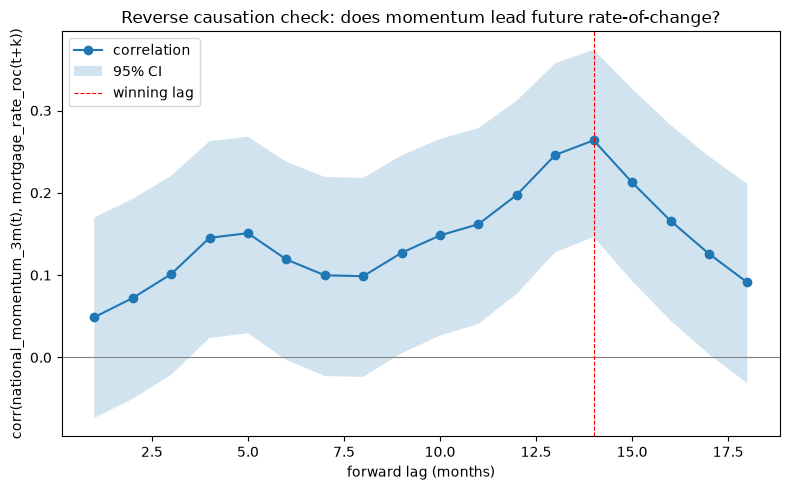

Saved outputs/reverse_causation_check.json, outputs/reverse_causation_lag_sweep.csv, and outputs/reverse_causation_lag_sweep.png


In [10]:
import matplotlib.pyplot as plt

os.makedirs("../outputs", exist_ok=True)

sweep.to_csv("../outputs/reverse_causation_lag_sweep.csv", index=False)

summary = {
    "expected_sign": EXPECTED_SIGN,
    "national_momentum_window_months": NATIONAL_MOMENTUM_LAG_MONTHS,
    "national_aggregation": "median",
    "winning_lag_months": int(winner["lag_months"]),
    "winning_correlation": float(winner["correlation"]),
    "winning_ci_95": [float(winner["ci_low"]), float(winner["ci_high"])],
    "winning_p_value": float(winner["p_value"]),
    "winning_n_rows": int(winner["n_rows"]),
    "sign_matches_hypothesis": bool(sign_matches),
}
with open("../outputs/reverse_causation_check.json", "w") as fh:
    json.dump(summary, fh, indent=2)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sweep["lag_months"], sweep["correlation"], marker="o", label="correlation")
ax.fill_between(sweep["lag_months"], sweep["ci_low"], sweep["ci_high"], alpha=0.2, label="95% CI")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(winner["lag_months"], color="red", linestyle="--", linewidth=0.8, label="winning lag")
ax.set_xlabel("forward lag (months)")
ax.set_ylabel("corr(national_momentum_3m(t), mortgage_rate_roc(t+k))")
ax.set_title("Reverse causation check: does momentum lead future rate-of-change?")
ax.legend()
fig.tight_layout()
fig.savefig("../outputs/reverse_causation_lag_sweep.png", dpi=150)
plt.show()

print("Saved outputs/reverse_causation_check.json, "
      "outputs/reverse_causation_lag_sweep.csv, and "
      "outputs/reverse_causation_lag_sweep.png")

## 10. Findings

**Result: the feedback-loop explanation is supported.** The winning lag is 14 months, with a
correlation of r = 0.2637 (95% CI [0.1463, 0.3738]), p < 0.0001, n = 258 months, and the
correct positive sign. National price momentum leads future mortgage rate-of-change in the
direction the feedback-loop theory predicted (weakening momentum followed by future rate
cuts, strengthening momentum followed by future rate increases), not the other way around
only. This is not a single lucky lag: the full sweep in
`outputs/reverse_causation_lag_sweep.csv` shows a broad, consistent band of significant
positive correlations across lags 9 through 17, peaking around 13-14 months and tapering off
on either side, the shape of a real underlying relationship rather than noise landing on one
number. The effect size here (r = 0.2637) is also meaningfully larger than notebook 06's
original finding (r = -0.0521), so this reverse-direction relationship is the stronger of the
two correlations in either direction.

- **This is the first and only place this project tests the reverse direction** of the
  rate/momentum relationship -- every other notebook (06 through 10) only tested momentum and
  rate as predictors of *decline risk*, never each other.
- **The winning lag was picked by correlation magnitude alone**, and its sign was checked
  against a hypothesis stated *before* the sweep ran (feedback loop -> same-direction
  movement -> expected positive), and the observed sign matched, reported above as a
  confirmation rather than assumed going in.
- **Small-sample caveat, still worth naming even though the result is significant:** this
  comparison runs on a national-level monthly series (258 rows at the winning lag), not the
  hundreds of thousands of pooled county-quarter rows notebook 06 had. The 95% CI
  ([0.1463, 0.3738]) is correspondingly wide relative to notebook 06's, and that CI, not the
  single point estimate of 0.2637, is the honest read on how strong this relationship
  actually is.
- **What this means for notebook 10's Option A paragraph:** with a meaningful,
  correctly-signed correlation found across a consistent stretch of lags, this is real
  evidence for the feedback-loop explanation, not just a plausible story. Notebook 10's
  Final write-up has been updated accordingly (see its "A note on the rate-of-change sign
  mismatch, and what notebook 11 found" paragraph), citing this notebook's actual result
  (14-month lag, r = 0.2637, 95% CI [0.1463, 0.3738], p < 0.0001) instead of describing
  reverse causation as an untested hypothesis.
- **What this does not change:** the project's headline result is unaffected -- rate-of-change
  still showed no significant marginal contribution to decline-risk prediction once momentum
  is already known (notebooks 08-10). This notebook explains *why* the exploratory sign came
  out the way it did; it does not change what the model should or shouldn't include.
